## Setup 

## Understanding A Gradient

A gradient tells us how changing a parameter affects the output or loss.

For the simple function:

y = w²

the derivative is:

dy/dw = 2w

At w = 3, the derivative is 6. This means that near w = 3,
a small increase in w will cause y to increase by approximately
6 times that change.

Neural-network training uses the same idea. The gradient of the
loss with respect to each weight tells the optimizer how changing
that weight would affect the loss.

In [6]:
import torch

# Create a scalar tensor with value 3.0.
# requires_grad=True tells PyTorch:
# "Track operations involving this number so that
# I can calculate derivatives later."
w = torch.tensor(
    3.0,
    requires_grad=True
)

# Define the function y = w^2.
y = w ** 2

print("w =", w.item())
print("y =", y.item())

w = 3.0
y = 9.0


In [7]:
# Calculate the derivative of y with respect to w.
y.backward()

# PyTorch stores the calculated gradient in w.grad.
print("Gradient calculated by PyTorch:", w.grad.item())

#Now it is basically saying that with this graident I can understand what is happening to my function y = w^2 with respect to changes in w. The gradient tells us how much y will change for a small change in w. In this case, the gradient is 6.0, which means that if we increase w by a small amount, y will increase by approximately 6 times that amount.

Gradient calculated by PyTorch: 6.0


## AutoGrad V.S. Finite Diffrence

## 3. Autograd vs. Finite Difference

A finite-difference gradient estimates a derivative by slightly changing a
parameter and measuring how much the output changes.

For a function f(w), the derivative can be approximated by:

(f(w + h) - f(w)) / h

where h is a very small number.

If h is small enough, this estimate should be close to the gradient calculated
by PyTorch autograd.

In [9]:
# Define the same function as before.
def f(w):
    return w ** 2

# Starting value.
w_value = 3.0

# Very small change in w.
h = 0.0001

# Calculate the function before changing w.
original_value = f(w_value)

# Calculate the function after increasing w slightly.
perturbed_value = f(w_value + h)

# Estimate the derivative using finite differences.
finite_difference_gradient = (
    perturbed_value - original_value
) / h

print("Original f(w):", original_value)
print("Perturbed f(w + h):", perturbed_value)
print(
    "Finite-difference gradient:",
    finite_difference_gradient
)

Original f(w): 9.0
Perturbed f(w + h): 9.000600010000001
Finite-difference gradient: 6.000100000012054


In [10]:
# Autograd calculation
w = torch.tensor(
    3.0,
    requires_grad=True
)

y = w ** 2
y.backward()

autograd_gradient = w.grad.item()

# Print the comparison.
print("Autograd gradient:", autograd_gradient)
print(
    "Finite-difference gradient:",
    finite_difference_gradient
)

print(
    "Difference:",
    abs(
        autograd_gradient
        - finite_difference_gradient
    )
)

Autograd gradient: 6.0
Finite-difference gradient: 6.000100000012054
Difference: 0.00010000001205412445


## 4. Load a Fixed Fashion-MNIST Subset


In [14]:
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader


# Point to the Q1 folder.
Q1_DIR = Path.cwd().parent

DATA_DIR = Q1_DIR / "data"
SPLIT_DIR = DATA_DIR / "split_indices"


# Use MPS if available.
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

Device: mps


In [16]:
import numpy as np

# Convert Fashion-MNIST images to tensors.
transform = transforms.ToTensor()

# Load the Fashion-MNIST training set.
full_train_dataset = datasets.FashionMNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

# Load the exact Week 1 training indices.
train_indices = np.load(
    SPLIT_DIR / "train_indices.npy"
)

print("Week 1 training examples:", len(train_indices))

Week 1 training examples: 10000


In [17]:
# Take only the first 32 examples from the fixed Week 1 training split.
tiny_indices = train_indices[:32]

tiny_dataset = Subset(
    full_train_dataset,
    tiny_indices
)

print("Tiny dataset size:", len(tiny_dataset))

Tiny dataset size: 32


In [19]:
#Puts all the 32 iamges into one bath
tiny_loader = DataLoader(
    tiny_dataset,
    batch_size=32,
    shuffle=False
)

images, labels = next(iter(tiny_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

Image batch shape: torch.Size([32, 1, 28, 28])
Label batch shape: torch.Size([32])
Labels: tensor([4, 1, 6, 5, 7, 2, 4, 4, 0, 3, 7, 7, 2, 8, 2, 6, 6, 4, 1, 8, 8, 3, 3, 1,
        1, 4, 1, 0, 3, 5, 5, 0])


In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(
            # 784 pixel values -> 128 hidden features
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            # 128 hidden features -> 64 hidden features
            nn.Linear(128, 64),
            nn.ReLU(),
            # 64 hidden features -> 10 class logits
            nn.Linear(64, 10)
        )
    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)
        return x

## 5. Tiny-Batch Overfit Test

A tiny-batch overfit test is a debugging technique.

Instead of training on thousands of examples, I train the model repeatedly on
only 32 examples. A neural network with enough capacity should eventually be able
to memorize such a small dataset and reach nearly 100% training accuracy.

If the model cannot overfit these 32 examples, that can indicate a problem in
the training pipeline, such as incorrect labels, missing gradients, an optimizer
problem, or an unsuitable learning rate.

This is not a test of generalization because the model is evaluated on the same
32 examples that it is trained on.

In [21]:
torch.manual_seed(42)

tiny_model = MLPClassifier().to(device)

tiny_loss_fn = nn.CrossEntropyLoss()

tiny_optimizer = optim.SGD(
    tiny_model.parameters(),
    lr=0.05
)

In [22]:
tiny_losses = []
tiny_accuracies = []

OVERFIT_EPOCHS = 200

for epoch in range(OVERFIT_EPOCHS):

    tiny_model.train()

    for images, labels in tiny_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous iteration.
        tiny_optimizer.zero_grad()

        # Forward pass.
        outputs = tiny_model(images)

        # Calculate loss.
        loss = tiny_loss_fn(
            outputs,
            labels
        )

        # Calculate gradients.
        loss.backward()

        # Update weights and biases.
        tiny_optimizer.step()
# Measure the preformance
    tiny_model.eval()

    with torch.no_grad():

        outputs = tiny_model(images)

        predictions = outputs.argmax(dim=1)

        accuracy = (
            predictions == labels
        ).float().mean().item()


    tiny_losses.append(loss.item())
    tiny_accuracies.append(accuracy)


    # Print every 20 epochs.
    if (
        epoch == 0
        or (epoch + 1) % 20 == 0
    ):

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy * 100:.2f}%"
        )

Epoch   1 | Loss: 2.3108 | Accuracy: 15.62%
Epoch  20 | Loss: 2.0914 | Accuracy: 15.62%
Epoch  40 | Loss: 1.7195 | Accuracy: 50.00%
Epoch  60 | Loss: 1.2515 | Accuracy: 65.62%
Epoch  80 | Loss: 0.8755 | Accuracy: 78.12%
Epoch 100 | Loss: 0.6200 | Accuracy: 90.62%
Epoch 120 | Loss: 0.4718 | Accuracy: 90.62%
Epoch 140 | Loss: 0.3209 | Accuracy: 90.62%
Epoch 160 | Loss: 0.1886 | Accuracy: 100.00%
Epoch 180 | Loss: 0.1279 | Accuracy: 100.00%
Epoch 200 | Loss: 0.0906 | Accuracy: 100.00%


## 6. Learning-Rate Experiment

This experiment investigates how the learning rate affects neural-network
training. I will train the same MLP architecture three times, using learning
rates of 0.001, 0.01, and 0.1.

I will keep the dataset, model architecture, initialization seed, and number
of training epochs fixed. This allows me to isolate the effect of changing
the learning rate.

For each experiment, I will record the loss, gradient norm, and parameter
change.

In [23]:
# Use the first 256 images from the saved Week 1 training split.
lr_indices = train_indices[:256]

# Create a fixed subset for the experiment.
lr_dataset = Subset(
    full_train_dataset,
    lr_indices
)

# Define the three learning rates.
learning_rates = [0.001, 0.01, 0.1]

# Train each model for the same number of epochs.
LR_EPOCHS = 25

print("Dataset size:", len(lr_dataset))
print("Learning rates:", learning_rates)
print("Epochs:", LR_EPOCHS)

Dataset size: 256
Learning rates: [0.001, 0.01, 0.1]
Epochs: 25


In [24]:
# Store the results of all three experiments.
learning_rate_results = {}

# Train a separate model for each learning rate.
for lr in learning_rates:

    print(f"\nTraining with learning rate: {lr}")

    # Reset the seed so each model starts from
    # the same initial weights and biases.
    torch.manual_seed(42)

    # Create a fresh MLP using the Week 2 architecture.
    model = MLPClassifier().to(device)

    # Use the same loss function.
    loss_fn = nn.CrossEntropyLoss()

    # Only the learning rate changes between experiments.
    optimizer = optim.SGD(
        model.parameters(),
        lr=lr
    )

    # Recreate the DataLoader with the same shuffle seed
    # so each model sees the batches in the same order.
    generator = torch.Generator().manual_seed(123)

    lr_loader = DataLoader(
        lr_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    # Store the measurements for every epoch.
    epoch_losses = []
    epoch_grad_norms = []
    epoch_parameter_changes = []

    for epoch in range(LR_EPOCHS):

        model.train()

        total_loss = 0.0
        total_grad_norm = 0.0
        total_parameter_change = 0.0

        for images, labels in lr_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Clear gradients from the previous batch.
            optimizer.zero_grad()

            # Forward pass: calculate the model's logits.
            outputs = model(images)

            # Calculate prediction loss.
            loss = loss_fn(outputs, labels)

            # Backpropagation: calculate gradients.
            loss.backward()

            # Calculate the total gradient norm across
            # all the model's trainable parameters.
            grad_norm = sum(
                parameter.grad.detach().pow(2).sum().item()
                for parameter in model.parameters()
                if parameter.grad is not None
            ) ** 0.5

            # Save copies of the parameters BEFORE
            # the optimizer changes them.
            old_parameters = [
                parameter.detach().clone()
                for parameter in model.parameters()
            ]

            # Update weights and biases.
            optimizer.step()

            # Measure how much the parameters actually changed.
            parameter_change = sum(
                (parameter.detach() - old).pow(2).sum().item()
                for parameter, old in zip(
                    model.parameters(),
                    old_parameters
                )
            ) ** 0.5

            # Record measurements for this batch.
            total_loss += loss.item()
            total_grad_norm += grad_norm
            total_parameter_change += parameter_change

        # Average the measurements across the epoch.
        num_batches = len(lr_loader)

        average_loss = total_loss / num_batches
        average_grad_norm = total_grad_norm / num_batches
        average_parameter_change = (
            total_parameter_change / num_batches
        )

        # Save this epoch's measurements.
        epoch_losses.append(average_loss)
        epoch_grad_norms.append(average_grad_norm)
        epoch_parameter_changes.append(
            average_parameter_change
        )

        # Print progress every five epochs.
        if (epoch + 1) % 5 == 0 or epoch == 0:

            print(
                f"Epoch {epoch + 1:2d} | "
                f"Loss: {average_loss:.4f} | "
                f"Gradient norm: {average_grad_norm:.4f} | "
                f"Parameter change: "
                f"{average_parameter_change:.6f}"
            )

    # Save all measurements for this learning rate.
    learning_rate_results[lr] = {
        "loss": epoch_losses,
        "gradient_norm": epoch_grad_norms,
        "parameter_change": epoch_parameter_changes
    }


Training with learning rate: 0.001
Epoch  1 | Loss: 2.3118 | Gradient norm: 0.5264 | Parameter change: 0.000526
Epoch  5 | Loss: 2.3085 | Gradient norm: 0.5637 | Parameter change: 0.000564
Epoch 10 | Loss: 2.3045 | Gradient norm: 0.5353 | Parameter change: 0.000535
Epoch 15 | Loss: 2.3007 | Gradient norm: 0.5754 | Parameter change: 0.000575
Epoch 20 | Loss: 2.2967 | Gradient norm: 0.5349 | Parameter change: 0.000535
Epoch 25 | Loss: 2.2928 | Gradient norm: 0.5279 | Parameter change: 0.000528

Training with learning rate: 0.01
Epoch  1 | Loss: 2.3093 | Gradient norm: 0.5309 | Parameter change: 0.005309
Epoch  5 | Loss: 2.2793 | Gradient norm: 0.5701 | Parameter change: 0.005701
Epoch 10 | Loss: 2.2387 | Gradient norm: 0.5996 | Parameter change: 0.005996
Epoch 15 | Loss: 2.1889 | Gradient norm: 0.6993 | Parameter change: 0.006993
Epoch 20 | Loss: 2.1216 | Gradient norm: 0.7415 | Parameter change: 0.007415
Epoch 25 | Loss: 2.0341 | Gradient norm: 0.8053 | Parameter change: 0.008053

Trai

## 9. Learning-Rate Plots

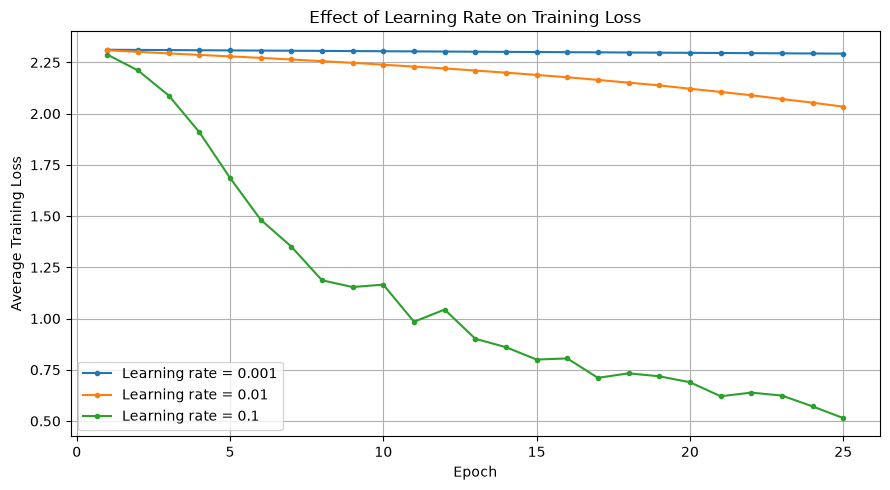

In [25]:

#AI CODE 
import matplotlib.pyplot as plt

# Make sure the folder exists.
FIGURES_DIR = Q1_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

epochs = range(1, LR_EPOCHS + 1)

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(
        epochs,
        learning_rate_results[lr]["loss"],
        marker="o",
        markersize=3,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("Effect of Learning Rate on Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "week03_learning_rate_loss.png",
    dpi=150
)

plt.show()

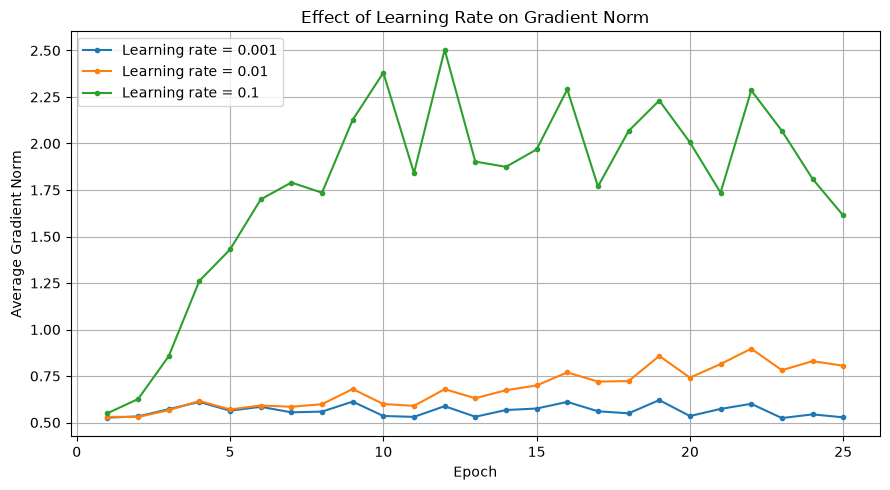

In [26]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(
        epochs,
        learning_rate_results[lr]["gradient_norm"],
        marker="o",
        markersize=3,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Average Gradient Norm")
plt.title("Effect of Learning Rate on Gradient Norm")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "week03_gradient_norm.png",
    dpi=150
)

plt.show()

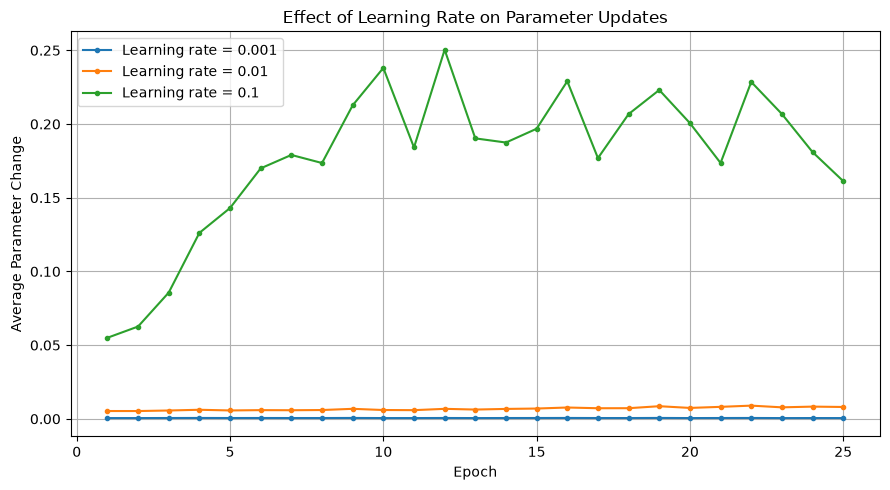

In [27]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:
    plt.plot(
        epochs,
        learning_rate_results[lr]["parameter_change"],
        marker="o",
        markersize=3,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Average Parameter Change")
plt.title("Effect of Learning Rate on Parameter Updates")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "week03_parameter_change.png",
    dpi=150
)

plt.show()

I compared three learning rates: 0.001, 0.01, and 0.1, while keeping the model architecture, dataset, initialization seed, batch order,
and training budget the same.

The learning rate of 0.001 resulted in very slow learning, with the training loss decreasing only from 2.3118 to 2.2928 after 25 epochs.

The learning rate of 0.01 reduced the loss to 2.0341, indicating faster learning.

The learning rate of 0.1 achieved the largest reduction in loss, reaching 0.5144 after 25 epochs.

The gradient-norm graph shows how the magnitude of the gradients changed throughout training. The parameter-change graph shows how much the optimizer updated the model's weights and biases.

These results demonstrate that the learning rate affects how quickly the optimizer moves through parameter space. In this experiment, 0.1 performed best over 25 epochs, but a larger learning rate is not necessarily better in every situation. It is supposed to be indivudalized per situation and per metric and despite being a hyper paramter in some situations can be adjusted. 

## 10. Debugging Checklist

THIS IS SO I DONT DO STUPID STUFF LIKE I DID THIS WEEK WHEN MAKING THIS MODEL

1. Dataset and Inputs
- [ ] The Fashion-MNIST dataset loads correctly.
- [ ] The input image shape is [32, 1, 28, 28].
- [ ] The model produces 10 logits per image.
- [ ] The labels contain valid class indices from 0 to 9.
2. Forward Pass and Loss
- [ ] The model completes a forward pass without errors.
- [ ] CrossEntropyLoss receives raw logits and the correct labels.
- [ ] The loss is a finite number (not NaN or infinity).

 3. Backpropagation
- [ ] optimizer.zero_grad() clears previous gradients.
- [ ] loss.backward() calculates gradients.
- [ ] The model has nonzero gradients during training.
- [ ] optimizer.step() changes the model's parameters.

4. Tiny-Batch Overfitting Test
- [ ] The experiment uses exactly 32 training examples.
- [ ] The model is repeatedly trained on those same examples.
- [ ] Training loss decreases substantially.
- [ ] Training accuracy approaches 100%.

5. Learning-Rate Experiment
- [ ] All three models use the same architecture.
- [ ] All three models start from the same random seed.
- [ ] The training data and batch ordering are fixed.
- [ ] The learning rates are 0.001, 0.01, and 0.1.
- [ ] Each model trains for 25 epochs.
- [ ] Loss, gradient norm, and parameter change are recorded.
- [ ] Three graphs are generated and saved.

6. Interpretation
- [ ] I can explain how the learning rate affects parameter updates.
- [ ] I can explain why a large learning rate can increase loss.
- [ ] I can explain why deliberately overfitting 32 examples helps with debugging.



## 11. Reflection

During Week 3, I investigated how gradients are calculated and how learning rates affect the training of neural networks.

First, I explored PyTorch's automatic differentiation using the function (f(w)=w^2). At (w=3), autograd calculated a derivative of 6. I compared this with a finite-difference approximation, which produced approximately the same result. This demonstrated how a gradient measures the sensitivity of a function to changes in its input.

Next, I explored the importance of debugging a training pipeline by attempting to overfit a dataset containing only 32 Fashion-MNIST images. The purpose of this experiment was to determine whether the network could learn a very small training dataset. This helps identify possible problems with the forward pass, loss calculation, backpropagation, or optimizer updates.

Finally, I compared three learning rates: 0.001, 0.01, and 0.1. After 25 epochs, the model using 0.001 reached a training loss of 2.2928, while the model using 0.01 reached 2.0341. The model using 0.1 performed best under these conditions, reaching a training loss of 0.5144.

